# Lab Deep Learning / LSTM + Transformer / in PyTorch Lightning

## Training a language model for generating sequences (One-to-Many)

**Author:** geoffroy.peeters@telecom-paris.fr  

**PyTorch Lightning version:** 2026/10/09

## Objective:

- We will train a network to learn a language model and then use it to generate new sequences.

- Instead of training the language model on text-documents (as it is the case in most examples) we will train it to learn the language of the music of [Johann_Sebastian_Bach](https://en.wikipedia.org/wiki/Johann_Sebastian_Bach).
For this, we will learn how J. S. Bach's "Cello suite" have been composed.
Here is an example of a "Cello suite" [Link](https://www.youtube.com/watch?v=mGQLXRTl3Z0).

- Rather than analyzing the audio signal, we use a symbolic representation of the "Cello suite" through their [MIDI files](https://en.wikipedia.org/wiki/MIDI#MIDI_files).
  - A MIDI file encodes in a file, the set of musical notes, their duration, and intensity which have to be played by each instrument to "render" a musical piece. The "rendering" is usually operated by a MIDI synthesizer (such as VLC, QuickTime) or a real performer (a musician reading a score).

- We will first train a language model on the whole set of MIDI files of the "Cello suites".
- We will then sample this language model to create a new MIDI file which will be a brand new "Cello suite" composed by the computer.


## Info

The neural networks are regular PyTorch `nn.Module` objects; PyTorch Lightning manages the training and validation loops, metrics, checkpoints, and early stopping.


## Import packages

In [1]:
!pip install torch lightning pretty_midi

import os
import glob
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import pretty_midi
import IPython

import torch
import torch.nn as nn
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from torch.utils.data import DataLoader, TensorDataset, random_split

# Use an Apple GPU (MPS) or CUDA GPU if available; otherwise use the CPU.
device = torch.device(
    "mps" if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)
student = True


Using device: cuda


# Get the data

In [6]:
# n_x --- the number of notes (here we consider the problem as a multi-class with n_x classes)
n_x = 79
# max_midi_T_x --- the maximum number of notes we read in each midi_file
max_midi_T_x = 1000
# model_T_x --- the length of the sequences considered for the LSTM/Transformer model
model_T_x = 100
# model_n_a --- the number of neurons of each layer of the network
model_n_a = 32

## Collect data to create the language model

We download the 36 MIDI files corresponding to the 36 "Cello suites" composed by J. S. Bach.

In [2]:
DIR = './'
import urllib.request
midi_file_l = ['cs1-2all.mid', 'cs5-1pre.mid', 'cs4-1pre.mid', 'cs3-5bou.mid', 'cs1-4sar.mid', 'cs2-5men.mid', 'cs3-3cou.mid', 'cs2-3cou.mid', 'cs1-6gig.mid', 'cs6-4sar.mid', 'cs4-5bou.mid', 'cs4-3cou.mid', 'cs5-3cou.mid', 'cs6-5gav.mid', 'cs6-6gig.mid', 'cs6-2all.mid', 'cs2-1pre.mid', 'cs3-1pre.mid', 'cs3-6gig.mid', 'cs2-6gig.mid', 'cs2-4sar.mid', 'cs3-4sar.mid', 'cs1-5men.mid', 'cs1-3cou.mid', 'cs6-1pre.mid', 'cs2-2all.mid', 'cs3-2all.mid', 'cs1-1pre.mid', 'cs5-2all.mid', 'cs4-2all.mid', 'cs5-5gav.mid', 'cs4-6gig.mid', 'cs5-6gig.mid', 'cs5-4sar.mid', 'cs4-4sar.mid', 'cs6-3cou.mid']
for midi_file in midi_file_l:
  #if os.path.isfile(DIR + midi_file) is None:
  urllib.request.urlretrieve ("http://www.jsbach.net/midi/" + midi_file, DIR + midi_file)

midi_file_l = glob.glob(DIR + 'cs*.mid')
print(midi_file_l)

['./cs4-1pre.mid', './cs2-6gig.mid', './cs5-4sar.mid', './cs3-1pre.mid', './cs1-1pre.mid', './cs6-1pre.mid', './cs6-4sar.mid', './cs3-5bou.mid', './cs5-3cou.mid', './cs2-4sar.mid', './cs1-2all.mid', './cs4-3cou.mid', './cs2-1pre.mid', './cs3-3cou.mid', './cs2-2all.mid', './cs6-2all.mid', './cs5-1pre.mid', './cs5-5gav.mid', './cs6-6gig.mid', './cs1-4sar.mid', './cs4-5bou.mid', './cs4-2all.mid', './cs5-6gig.mid', './cs6-5gav.mid', './cs4-6gig.mid', './cs2-3cou.mid', './cs3-4sar.mid', './cs1-3cou.mid', './cs2-5men.mid', './cs1-5men.mid', './cs4-4sar.mid', './cs1-6gig.mid', './cs3-2all.mid', './cs6-3cou.mid', './cs5-2all.mid', './cs3-6gig.mid']


## Read and convert all MIDI files

We illustrate here the content of a MIDI file. Each file contains a list of notes to be played over time. Each note is characterized by
- its `pitch` (in MIDI note number, la3=A4=69)
- its `start` time (when to start playing the note)
- its `stop` time (when to stop playing the note)
- its `duration` (which is computed as stop-start)

In [3]:
# --- Read a single MIDI file
midi_data = pretty_midi.PrettyMIDI(midi_file_l[0])
# --- Display the note pitch, start, end and duration
for note in midi_data.instruments[0].notes[:20]:
    print('pitch: %d, start: %f, end: %f, duration: %f' % (note.pitch, note.start, note.end, note.end-note.start))

pitch: 39, start: 0.000000, end: 0.312500, duration: 0.312500
pitch: 63, start: 0.312500, end: 0.625000, duration: 0.312500
pitch: 58, start: 0.625000, end: 0.937500, duration: 0.312500
pitch: 55, start: 0.937500, end: 1.250000, duration: 0.312500
pitch: 58, start: 1.250000, end: 1.562500, duration: 0.312500
pitch: 51, start: 1.562500, end: 1.875000, duration: 0.312500
pitch: 55, start: 1.875000, end: 2.187500, duration: 0.312500
pitch: 46, start: 2.187500, end: 2.500000, duration: 0.312500
pitch: 39, start: 2.500000, end: 2.812500, duration: 0.312500
pitch: 63, start: 2.812500, end: 3.125000, duration: 0.312500
pitch: 58, start: 3.125000, end: 3.437500, duration: 0.312500
pitch: 55, start: 3.437500, end: 3.750000, duration: 0.312500
pitch: 58, start: 3.750000, end: 4.062500, duration: 0.312500
pitch: 51, start: 4.062500, end: 4.375000, duration: 0.312500
pitch: 55, start: 4.375000, end: 4.687500, duration: 0.312500
pitch: 46, start: 4.687500, end: 5.000000, duration: 0.312500
pitch: 3

We read each MIDI file and for each only retains the `pitch` (we name it `note`) information.
We convert the list of `note`  to a one-hot-encoding matrix X_ohe of dimensions `(midi_T_x, n_x)` where `n_x` is the number of possible musical notes.
The length of the sequences `midi_T_x` can vary from one sequence to the other.



In [33]:
def F_convert_midi_2_list(midi_file_l, max_midi_T_x):
    """
    read the notes within all midi files
    truncate the length if > max_midi_T_x

    Parameters
    ----------
    midi_file_l:
        list of MIDI files
    max_midi_T_x:
        the maximum number of notes we read in a given midi_file

    Returns
    -------
    X_list:
        a list of np.array X_ohe of size (midi_T_x, n_x) which contains the one-hot-encoding representation of notes over time
    """
    X_list = []

    for midi_file in midi_file_l:
        # --- read the MIDI file
        midi_data = pretty_midi.PrettyMIDI(midi_file)
        note_l = [note.pitch for note in midi_data.instruments[0].notes]
        midi_T_x = len(note_l) if len(note_l) < max_midi_T_x else max_midi_T_x
        if student:
            # --- START CODE HERE (01)
            X_ohe = np.zeros((midi_T_x, n_x))
            notes = np.array(note_l[:midi_T_x])
            X_ohe[np.arange(midi_T_x), notes - 1] = 1
            # --- END CODE HERE

        X_list.append(X_ohe)

    return X_list

In [34]:
X_list = F_convert_midi_2_list(midi_file_l, max_midi_T_x)
print(len(X_list))
print(X_list[0].shape)
print(X_list[1].shape)
print(X_list[2].shape)

36
(789, 79)
(690, 79)
(216, 79)


## Display the set of notes over time for a specific track

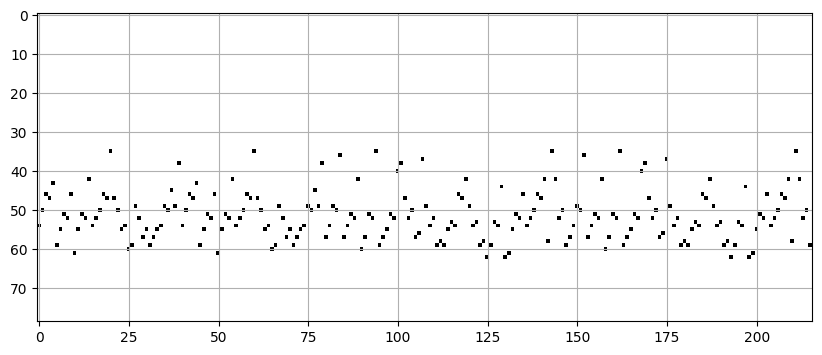

In [35]:
plt.figure(figsize=(10, 4))
plt.imshow(X_list[2].T, aspect='auto')
plt.set_cmap('gray_r')
plt.grid(True)

## Data conversion for the training of language model

We want to train a language model, i.e. a model thats predict a note given past notes: $p(x^{<\tau>} | x^{<1>}, x^{<2>}, ... x^{<\tau-1>})$.

A simple way to do this is to create (for each MIDI sequence and for each possible starting note `t` within this MIDI sequence) two sequences:
- an input sequence $x$:
  - which contains a sub-sequence of length `model_T_x`;  this sub-sequence range from `t` to `t+model_T_x-1`
- an output sequence $y$ :
  - which contains the same sub-sequence but delayed by one time step: ranging from `t+1` to `t+model_T_x`

<img src="https://perso.telecom-paristech.fr/gpeeters/doc/Lab_DL_RNN_03.png">



In [36]:
def F_convert_list_2_data(X_list, model_T_x, sequence_step=1):
    """
    convert X_list to input X_train and output Y_train training data

    Parameters
    ----------
    X_list:
        a list of np.array X_ohe of size (midi_T_x, n_x) which contains the one-hot-encoding representation of notes over time

    Returns
    -------
    X_train:
        the set of all m input sequences; np.array of shape (m, model_T_x, n_x)
    Y_train:
        the set of all m output sequences; np.array of shape (m, model_T_x, n_x)

            note:   m is the total number of training items,
                    it is be larger than the number of MIDI files since we use several starting time t in each MIDI file
    """

    if student:
      # --- START CODE HERE (02)
      X_train_list = []
      Y_train_list = []

      for X in X_list:
          for t in range(0, X.shape[0] - model_T_x, sequence_step):
              X_train_list.append(X[t : t + model_T_x])
              Y_train_list.append(X[t + 1 : t + model_T_x + 1])
      # --- END CODE HERE

    X_train = np.asarray(X_train_list)
    Y_train = np.asarray(Y_train_list)

    return X_train, Y_train

X_train.shape: (20901, 100, 79)
Y_train.shape: (20901, 100, 79)


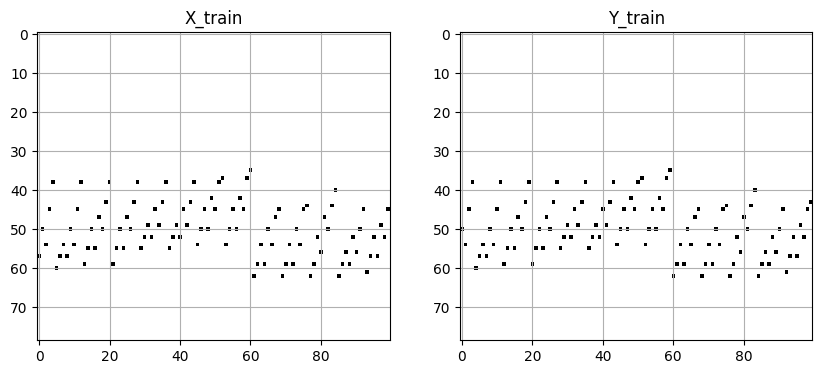

In [37]:
X_train, Y_train = F_convert_list_2_data(X_list, model_T_x)
# --- X_train is of shape (m, model_T_x, n_x)
print("X_train.shape:", X_train.shape)
# --- Y_train is of shape (m, model_T_x, n_x)
print("Y_train.shape:", Y_train.shape)


plt.figure(figsize=(10, 4))
plt.subplot(1,2,1); plt.imshow(X_train[20,:,:].T, aspect='auto'); plt.grid(True); plt.title('X_train')
plt.subplot(1,2,2); plt.imshow(Y_train[20,:,:].T, aspect='auto'); plt.grid(True); plt.title('Y_train')
plt.set_cmap('gray_r')

# Training the language model

To learn the language model we will train an LSTM or a Transformer with input `X_train` and output `Y_train`.  
For each example, we give to the network a sequence of notes from `t` to `t+model_T_x-1`  and ask the network to predict the following note of each sequence `t+1` to `t+model_T_x`.
We already created those in `X_train` and `Y_train`.




## Model 1: using LSTM
The network architecture is the following:
- (1a) a layer of `LSTM` with `model_n_a` units
- (1b) a layer of DropOut with rate 0.3 (the probability to "drop-out" one neuron is 0.3)
- (2a) a layer of `LSTM` with `model_n_a` units
- (2b) a layer of DropOut with rate 0.3 (the probability to "drop-out" one neuron is 0.3)
- (3) a layer of `LSTM` with `model_n_a` units
- (4a) a layer of `Linear` with `model_n_a` units with a `tanh` activation
- (4b) a layer of DropOut with rate 0.3 (the probability to "drop-out" one neuron is 0.3)
- (5) a layer of `Linear` with a `softmax` activation which predict the probability of each of the $n_x$ notes as output

### Info

By default `nn.LSTM` in pytorch outputs `output, (h_n, c_n)`:
- `output` is the hidden states for each time
- `h_n, c_n` are the final hidden state and memory cell.

We transmit `output` to the next layer.

see https://docs.pytorch.org/docs/2.14/generated/torch.nn.LSTM.html

Please keep in mind that the `softmax` is already included in our loss (`nn.CrossEntropyLoss`) and is usually not included at the end of the network.

In [38]:
# --- Create Model 1: LSTM language model
if student:
    # --- START CODE HERE (03)
    class BachLSTMNet(nn.Module):
        def __init__(self, n_x, model_T_x, model_n_a):
            super().__init__()
            self.lstm1 = nn.LSTM(n_x, model_n_a, batch_first=True)
            self.dropout1 = nn.Dropout(0.3)
            self.lstm2 = nn.LSTM(model_n_a, model_n_a, batch_first=True)
            self.dropout2 = nn.Dropout(0.3)
            self.lstm3 = nn.LSTM(model_n_a, model_n_a, batch_first=True)
            self.linear1 = nn.Linear(model_n_a, model_n_a)
            self.tanh = nn.Tanh()
            self.dropout3 = nn.Dropout(0.3)
            self.linear2 = nn.Linear(model_n_a, n_x)

        def forward(self, X):
            X, _ = self.lstm1(X)
            X = self.dropout1(X)
            X, _ = self.lstm2(X)
            X = self.dropout2(X)
            X, _ = self.lstm3(X)
            X = self.linear1(X)
            X = self.tanh(X)
            X = self.dropout3(X)
            X = self.linear2(X)
            return X

    # --- END CODE HERE


model = BachLSTMNet(n_x, model_T_x, model_n_a)
print(X_train.shape)
with torch.no_grad():
    print(model(torch.tensor(X_train[:64], dtype=torch.float32)).shape)
print(model)
print("Number of trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


(20901, 100, 79)
torch.Size([64, 100, 79])
BachLSTMNet(
  (lstm1): LSTM(79, 32, batch_first=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (lstm2): LSTM(32, 32, batch_first=True)
  (dropout2): Dropout(p=0.3, inplace=False)
  (lstm3): LSTM(32, 32, batch_first=True)
  (linear1): Linear(in_features=32, out_features=32, bias=True)
  (tanh): Tanh()
  (dropout3): Dropout(p=0.3, inplace=False)
  (linear2): Linear(in_features=32, out_features=79, bias=True)
)
Number of trainable parameters: 35023


## Model 2: using Transformer

### Positional encoding

We first start by creating the **positional encoding** that needs to be added to the input `X` during the forward pass.
This is the goal of the function `F_positional_encoding`.
We use the positional encoding proposed in [Vaswani et al. "Attention Is All You Need", NIPS, 2017].
$$
angle(pos,d) = \frac{pos}{10000^{2d/D}}\\
PE(pos,2d)=\sin \left( angle(pos,d) \right)\\
PE(pos,2d+1)=\cos \left( angle(pos, d) \right)
$$

In this
- `pos` is the temporal position (which ranges from 0 to `model_T_x` in our case);
- `d`is the dimension (which ranges from 0 to `n_x` in our case)


(1, 100, 79)


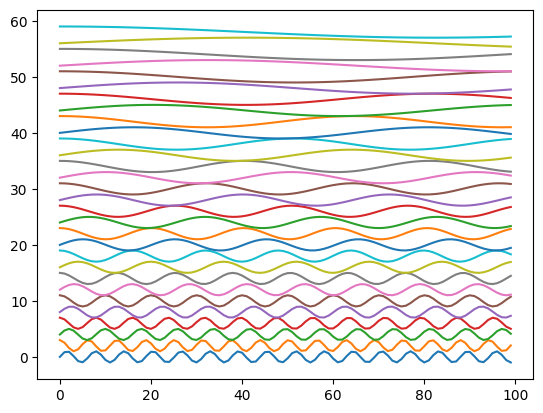

In [39]:
def F_positional_encoding(model_T_x, n_x):
    """
    arguments
        model_T_x: length of the sequence
        n_x: number of dimensions
    return
        PE_m: positional embedding matrix of dimensions (1, pos_v, dim_v)
    """
    if student:
        # --- START CODE HERE (04)
        pos_v = np.arange(model_T_x)[:, np.newaxis]
        d_v = np.arange(n_x)[np.newaxis, :]
        angle_rate_m = F_get_angles(pos_v, d_v, n_x)

        PE_m = np.zeros((model_T_x, n_x))
        PE_m[:, 0::2] = np.sin(angle_rate_m[:, 0::2])
        PE_m[:, 1::2] = np.cos(angle_rate_m[:, 1::2])

        PE_m = PE_m[np.newaxis, :, :]
        return PE_m

def F_get_angles(pos_v, d_v, D):
    """
    arguments
        pos_v: np.array with all positions
        d_v: np.array with all dimensions
        D: total number of dimensions
    return
        angle_m of dimensions (len(pos_v), len(d_v))
    """
    if student:
        # --- START CODE HERE (04)
        angle_m = pos_v / np.power(10000, (2 * (d_v // 2)) / D)
        # --- END CODE HERE
        return angle_m

PE_m = F_positional_encoding(model_T_x, n_x)
print(PE_m.shape)
for d in range(30):
    plt.plot(2*d+PE_m[0,:,d])

We need to write an auto-regressive model which is usually the goal of the decoder part of a Transformer.

However, given that we do not condition the decoder on an encoder output, we do not need the Encoder-Decoder Cross-Attention.
Therefore the decoder blocks are similar to the encoder blocks apart from the masking of the future.

For implementation we therefore use the ready-to-be-used module `nn.TransformerEncoderLayer` (one encoder block) which is encapsulated into `nn.TransformerEncoder` (all the blocks).
See
- https://docs.pytorch.org/docs/2.14/generated/torch.nn.TransformerEncoderLayer.html#torch.nn.TransformerEncoderLayer
- https://docs.pytorch.org/docs/2.14/generated/torch.nn.TransformerEncoder.html

(1) We first embed (project) the data (n_x dimensions) into the dimensions of the model (d_model) using `nn.Linear`.

(2) We then add our positional_encoding as defined by `F_positional_encoding`.

(3) We enter the layers of the Transformer encoder.
To prevent the use of future tokens, we apply a mask.
The mask is created using `nn.Transformer.generate_square_subsequent_mask`.
`nn.TransformerEncoder` allows to use this mask during its forward pass and specifying `is_causal=True`.

(4) We finally projet back the output of the transformer (d_model) to the dimensions of the data (n_x) using a second `nn.Linear`.

Our transformer will have 4 layers each with 2 heads and a gelu. But don't worry we provide you this part of the code.



In [41]:
if student:
    # --- START CODE HERE (05)
    class BachNet(nn.Module):
        def __init__(self, n_x, model_T_x, num_layers, num_heads, intermediate_dim, dropout, d_model=80):
            super().__init__()
            self.input_projection = nn.Linear(n_x, d_model)
            self.register_buffer("positional_encoding", torch.tensor(F_positional_encoding(model_T_x, d_model), dtype=torch.float32))
            self.register_buffer("causal_mask", nn.Transformer.generate_square_subsequent_mask(model_T_x))
            decoder_layer = nn.TransformerEncoderLayer(
                d_model=d_model, nhead=num_heads, dim_feedforward=intermediate_dim,
                dropout=dropout, activation="gelu", batch_first=True, norm_first=False
            )
            self.decoder = nn.TransformerEncoder(decoder_layer, num_layers=num_layers)
            self.output_projection = nn.Linear(d_model, n_x)

        def forward(self, X):
            T = X.size(1)
            X = self.input_projection(X)
            X = X + self.positional_encoding[:, :T, :]
            X = self.decoder(X, mask=self.causal_mask[:T, :T], is_causal=True)
            X = self.output_projection(X)
            return X

    # --- STOP CODE HERE (05)


model = BachNet(n_x=n_x, model_T_x=model_T_x, num_layers=4,
                num_heads=2, intermediate_dim=128, dropout=0.1, d_model=80)
print(X_train.shape)
with torch.no_grad():
    print(model(torch.tensor(X_train[:64], dtype=torch.float32)).shape)
print(model)
print("Number of trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


(20901, 100, 79)
torch.Size([64, 100, 79])
BachNet(
  (input_projection): Linear(in_features=79, out_features=80, bias=True)
  (decoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=80, out_features=80, bias=True)
        )
        (linear1): Linear(in_features=80, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=80, bias=True)
        (norm1): LayerNorm((80,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((80,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output_projection): Linear(in_features=80, out_features=79, bias=True)
)
Number of trainable parameters: 200511


# Train Model 1 and Model 2 with PyTorch Lightning


PyTorch Lightning keeps the model definition separate from the training procedure. We wrap the selected PyTorch model in a `LightningModule`, which defines the loss, the optimizer, and the training and validation steps.

`Trainer.fit` then manages the epochs and devices. `EarlyStopping` stops training after three epochs without an improvement in validation loss; `ModelCheckpoint` retains the best weights, which are restored after training.


In [42]:
# --- Create PyTorch datasets and loaders
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(np.argmax(Y_train, axis=-1), dtype=torch.long)
dataset = TensorDataset(X_tensor, y_tensor)

n_val = max(1, int(0.1 * len(dataset)))
n_train = len(dataset) - n_val
train_set, val_set = random_split(dataset, [n_train, n_val], generator=torch.Generator().manual_seed(0))
train_loader = DataLoader(train_set, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_set, batch_size=16, num_workers=0)

class BachLightningModule(pl.LightningModule):
    def __init__(self, network, learning_rate=1e-3):
        super().__init__()
        self.network = network
        self.learning_rate = learning_rate
        self.criterion = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.network(x)

    def _shared_step(self, batch, stage):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits.reshape(-1, n_x), y.reshape(-1))
        accuracy = (logits.argmax(dim=-1) == y).float().mean()
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=True, batch_size=x.shape[0])
        self.log(f"{stage}_accuracy", accuracy, on_step=False, on_epoch=True, prog_bar=True, batch_size=x.shape[0])
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.learning_rate)

lit_model = BachLightningModule(model)
early_stopping = EarlyStopping(monitor="val_loss", mode="min", patience=3)
checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)
trainer = pl.Trainer(
    max_epochs=100,
    accelerator="auto",
    devices=1,
    callbacks=[early_stopping, checkpoint],
    logger=False,
    enable_model_summary=True,
)
trainer.fit(lit_model, train_dataloaders=train_loader, val_dataloaders=val_loader)

# Restore the best validation-loss checkpoint, then use the underlying nn.Module for sampling.
best_checkpoint = torch.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
lit_model.load_state_dict(best_checkpoint["state_dict"])
model = lit_model.network
model.eval()
print("Best checkpoint:", checkpoint.best_model_path)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ network   │ BachNet          │  200 K │ train │     0 │
│ 1 │ criterion │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 200 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 200 K                                                                                                
Total estimated model params size (MB): 0.802                                                                      
Modules in train mode: 46                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

Best checkpoint: /content/checkpoints/epoch=47-step=56448.ckpt


# Generating a new sequence by sampling the language model

To generate a new sequence from the language model,

- we first randomly choose a starting note among the `n_x` possible ones. For this you can use `
torch.multinomial` and either
    - assume an uniform distribution
    - compute a prior note distribution (you can do this by computing the number of occurences of each notes in the training set)
- we then create an artificial input `x` that can be used by our model. Our model requires data `x` of shape `(m, model_T_x, n_x)`. In our case
    - `m=1` since we have only one sequence,
    - `model_T_x` should be the length used when training our model so it is `model_T_x` and
    - `n_x` is the number of notes.
- we set the data at time `t=0`, `x[0,0,:]`, to our random note (after converting it to a one-hot-encoding)
- we then feed our model with this data. The model has been trained to predict $p(x^{<\tau>} | x^{<1>}, x^{<2>}, ... x^{<\tau-1>})$.
The output of the model `y` is of shape `(m, model_T_x, n_x)`. But only the first value is meaningfull so far.
The output value `y` at `t=0` is $p(x^{<1>} | x^{<0>})$, i.e. the probability of each note to be the second note given our first note as input. Actually `y` at `t=0` (noted `y[0,0,:]`) is a vector that represents the probability of each of the `n_x` notes given the one at `t=0`. We can then either
    - (a) get the most likely class from the vector `y[0,0,:]` (`np.argmax`) or
    - (b) consider the vector `y[0,0,:]` as a multinomial distribution and sample from it (`torch.multinomial`). If the vector is too peaky (one of the probability is much larger than the other) we can flatten it using a temperature scaling (see below).
- whathever (a) or (b), the selected note is now considered as the note at `t=1`. We therefore add it (after conversion to one-hot-encoding) to the input data $x$ at time `t=1`: `x[0,1,:]`.
- we then feed our model with this new `x`. The output of the model at `t=1`, `y[0,1,:]`, is $p(x^{<2>} | x^{<0>}, x^{<1>})$. We then either perform (a) or (b), plugs the new selected notes as the input $x$ at `t=2`, `x[0,2,:]`, and repeat the process for the following times until we reach `model_T_x`.



## Info

The PyTorch models return logits. For sampling, they are converted to a probability distribution using `torch.softmax(logits / temperature)`. At each time step, we sample a note with `torch.multinomial`, append its one-hot representation to the input, and predict the next note.


In [43]:
def F_sample_new_sequence(model, prior_v, temperature=1.0):
    """
    sample the trained language model to generate new data

    Parameters
    ----------
    model:
        trained language model
    prior_v:
        prior probablity for each n_x
    temperature:
        to apply to the softmax for sharpening or flattening the distribution

    Returns
    -------
    note_l: list of int
        list of generated notes (list of their index)
    prediction_l: list of np.array(n_x)
        list of prediction probabilies over time t (each entry of the list is one of the y[0,t,:])
    """

    model.eval()
    prediction_l, note_l = [], []
    model_device = next(model.parameters()).device
    input_3m = torch.zeros((1, model_T_x, n_x), dtype=torch.float32, device=model_device)
    first_note = np.random.multinomial(1, prior_v).argmax()
    input_3m[0, 0, first_note] = 1.0

    with torch.no_grad():
        if student:
            # --- START CODE HERE (06)
            for t in range(model_T_x - 1):
                # Predict the next note
                logits = model(input_3m)

                # Convert logits at time t into probabilities
                probabilities = torch.softmax(logits[0, t, :] / temperature, dim=-1)
                prediction_l.append(probabilities.cpu().numpy())

                # Sample the next note
                next_note = torch.multinomial(probabilities, num_samples=1).item()

                # Add it to the sequence as a one-hot vector
                input_3m[0, t + 1, next_note] = 1.0
                note_l.append(next_note)
            # --- END CODE HERE

    return note_l, prediction_l


### Display the generated sequence

[62, 54, 62, 41, 44, 47, 50, 47, 53, 47, 56, 49, 53, 56, 59, 56, 61, 56, 42, 46, 54, 54, 49, 54, 45, 49, 42, 40, 57, 54, 49, 54, 45, 49, 42, 38, 57, 54, 49, 54, 45, 49, 42, 37, 57, 54, 49, 54, 45, 49, 42, 36, 48, 49, 51, 53, 54, 56, 57, 56, 54, 53, 54, 51, 48, 49, 51, 53, 54, 56, 57, 56, 54, 56, 57, 59, 61, 59, 62, 61, 59, 57, 56, 57, 59, 57, 56, 54, 53, 54, 37, 59, 56, 53, 56, 49, 53, 44, 37]


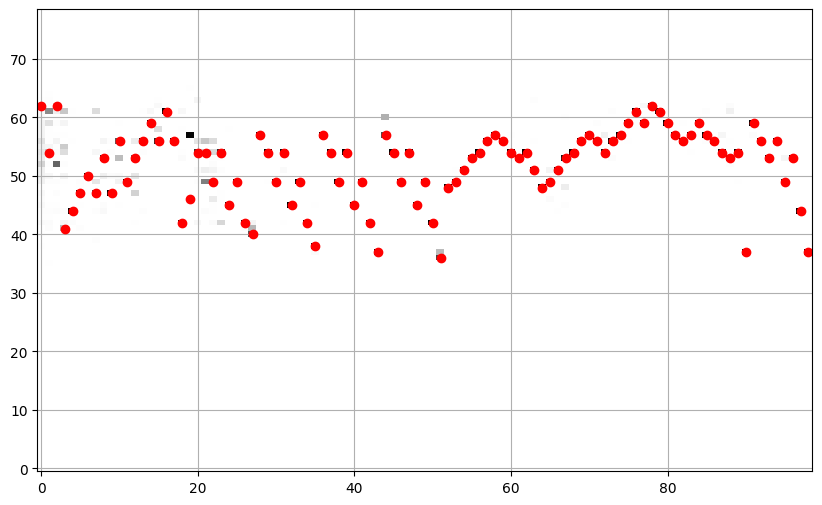

In [44]:
if False:
    prior_v = np.ones(n_x) / n_x
else:
    sum_v = np.zeros(n_x)
    for X_ohe in X_list:
        sum_v += np.sum(X_ohe, axis=0)
    prior_v = sum_v / np.sum(sum_v)

note_l, prediction_l = F_sample_new_sequence(model, prior_v)

print(note_l)
plt.figure(figsize=(10, 6))
plt.imshow(np.asarray(prediction_l).T, aspect='auto', origin='lower')
plt.plot(note_l, 'ro')
plt.set_cmap('gray_r')
plt.grid(True)


### Create a MIDI file and an audio file which correspond to the generated sequence

Once the new sequence has been generated (`note_l`) we transform it to a new MIDI file and perform (a very cheap) rendering of it in an audio file.

In [45]:
new_midi_data = pretty_midi.PrettyMIDI()
cello_program = pretty_midi.instrument_name_to_program('Cello')
cello = pretty_midi.Instrument(program=cello_program)
time, step = 0, 0.3
for note_index in note_l:
    # The one-hot index 0 corresponds to MIDI pitch 1.
    myNote = pretty_midi.Note(velocity=100, pitch=int(note_index + 1), start=time, end=time + step)
    cello.notes.append(myNote)
    time += step
new_midi_data.instruments.append(cello)
new_midi_data.write('output.mid')


In [46]:
%matplotlib inline
audio_data = new_midi_data.synthesize(fs=44100)
IPython.display.Audio(audio_data, rate=44100)

Output hidden; open in https://colab.research.google.com to view.

# Evaluation

To evaluate the work, you should rate the code for
- 1) MIDI conversion to one-hot-encoding: `F_convert_midi_2_list` (01)
- 2) Data conversion for the training of language model `F_convert_list_2_data` (02)
- 3) Training the language model using Model 1 (LSTM) (03)
- 4) Training the language model using Model 2 (`F_positional_encoding`and Transformer) (04,05)
- 5) Generating a new sequence from sampling the language model `F_sample_new_sequence` (06)

